# Resume / Candidate Screening System
**Future Interns · Machine Learning Track · Task 3 (`FUTURE_ML_03`)**

## Business scenario
A company opens a role and receives hundreds of resumes. Recruiters spend minutes on each one, decisions vary
from person to person, and strong candidates get buried in the pile. This notebook builds a screening assistant that:

1. **Parses** messy resume text into structured fields (skills, experience, education)
2. **Reads a job description** and works out what is required and what is nice to have
3. **Ranks every candidate** by role fit, with a score that can be explained
4. **Identifies skill gaps** for each candidate and across the whole applicant pool

The system is a decision aid. It sorts the pile so humans spend their time on the best matches. It does not
make hiring decisions on its own.

## Workflow
1. Load resumes, 2. Clean and parse, 3. Extract skills, 4. Parse job descriptions, 5. Build the ranking model,
6. Evaluate it against simpler approaches, 7. Rank candidates for a role, 8. Skill gap analysis, 9. Screen any new job description

In [1]:
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ndcg_score, average_precision_score

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25})

# ---- Configuration -------------------------------------------------------
SEED = 42
DATA_PATH = None                 # None = built-in simulated resumes; or a CSV with "Category" and "Resume" columns
TARGET_ROLE = "Data Scientist"   # the role we screen for in the main walkthrough
TOP_N = 10
# How much each signal contributes to the final 0-100 fit score (must add up to 1)
WEIGHTS = {"tfidf": 0.30, "skills": 0.35, "role_fit": 0.20, "experience": 0.075, "education": 0.075}
assert abs(sum(WEIGHTS.values()) - 1) < 1e-9

IMG_DIR = Path("images");  IMG_DIR.mkdir(exist_ok=True)
OUT_DIR = Path("outputs"); OUT_DIR.mkdir(exist_ok=True)
C = {"blue": "#2563eb", "grey": "#9ca3af", "green": "#16a34a", "red": "#dc2626", "amber": "#d97706", "dark": "#1f2937"}

## 1. Skill taxonomy
Skill matching needs a vocabulary. Each skill has a **canonical name** and the **aliases** people actually write
(`sklearn`, `k8s`, `ReactJS`). Matching is case-insensitive and respects word boundaries, so `java` never matches inside
`javascript` and `sql` never matches inside `mysql`.

In [2]:
SKILLS = {
    # data science / analytics
    "python": ["python"], "machine learning": ["machine learning", "ml"], "deep learning": ["deep learning"],
    "tensorflow": ["tensorflow"], "pytorch": ["pytorch"],
    "scikit-learn": ["scikit-learn", "sklearn", "scikit learn"], "pandas": ["pandas"], "numpy": ["numpy"],
    "nlp": ["nlp", "natural language processing"], "statistics": ["statistics", "statistical analysis"],
    "sql": ["sql"], "data visualization": ["data visualization", "data visualisation", "matplotlib", "seaborn"],
    "jupyter": ["jupyter"], "feature engineering": ["feature engineering"],
    "a/b testing": ["a/b testing", "ab testing"], "data cleaning": ["data cleaning", "data wrangling", "data cleansing"],
    "excel": ["excel", "ms excel", "microsoft excel", "advanced excel"], "power bi": ["power bi", "powerbi"],
    "tableau": ["tableau"], "reporting": ["reporting", "report automation"], "dashboards": ["dashboard", "dashboards"],
    "etl": ["etl"], "google analytics": ["google analytics"],
    # web
    "html": ["html", "html5"], "css": ["css", "css3"], "javascript": ["javascript", "js", "es6"],
    "typescript": ["typescript"], "react": ["react", "reactjs", "react.js"],
    "node.js": ["node.js", "nodejs", "node js"], "express": ["express", "express.js"],
    "rest api": ["rest api", "rest apis", "restful api", "restful apis", "restful services"],
    "mongodb": ["mongodb", "mongo db"], "responsive design": ["responsive design", "responsive web design"],
    "git": ["git", "github"],
    # backend
    "java": ["java"], "spring boot": ["spring boot", "springboot"], "hibernate": ["hibernate"],
    "microservices": ["microservices", "microservice"], "mysql": ["mysql", "postgresql", "postgres"],
    "maven": ["maven"], "junit": ["junit"], "kafka": ["kafka", "apache kafka"],
    # devops
    "docker": ["docker"], "kubernetes": ["kubernetes", "k8s"], "aws": ["aws", "amazon web services"],
    "terraform": ["terraform"], "jenkins": ["jenkins"],
    "ci/cd": ["ci/cd", "cicd", "ci cd", "continuous integration"], "linux": ["linux"], "ansible": ["ansible"],
    "bash": ["bash", "shell scripting", "shell script"], "prometheus": ["prometheus"], "grafana": ["grafana"],
    "monitoring": ["monitoring", "observability"],
    # project management
    "agile": ["agile"], "scrum": ["scrum"], "jira": ["jira"],
    "stakeholder management": ["stakeholder management", "stakeholder engagement"],
    "risk management": ["risk management", "risk assessment"], "budgeting": ["budgeting", "budget management"],
    "ms project": ["ms project", "microsoft project"], "communication": ["communication", "communication skills"],
    "pmp": ["pmp"], "project planning": ["project planning", "project scheduling"], "leadership": ["leadership"],
}


def _alias_regex(alias):
    return re.compile(r"(?<![\w])" + re.escape(alias) + r"(?![\w])", re.I)


SKILL_PATTERNS = {canon: [_alias_regex(a) for a in sorted(aliases, key=len, reverse=True)] for canon, aliases in SKILLS.items()}
ALIAS_TO_CANON = sorted(((a, canon) for canon, al in SKILLS.items() for a in al), key=lambda x: -len(x[0]))
ALIAS_REGEX = [(_alias_regex(a), canon.replace(" ", "_").replace("/", "_").replace(".", "_").replace("-", "_")) for a, canon in ALIAS_TO_CANON]


def extract_skills(text):
    # Return the canonical skills mentioned in a piece of text.
    return sorted(c for c, pats in SKILL_PATTERNS.items() if any(p.search(text) for p in pats))


print(f"{len(SKILLS)} skills, {sum(len(v) for v in SKILLS.values())} aliases")
print(extract_skills("Built models with Sklearn and PyTorch, shipped on K8s. Strong JavaScript + MySQL."))

65 skills, 117 aliases
['javascript', 'kubernetes', 'mysql', 'pytorch', 'scikit-learn']


## 2. Resume data
The task allows any resume dataset. This notebook ships with **simulated resumes for fictional candidates**, so it
runs anywhere and contains no real personal data. 360 resumes across six roles, written in varied styles
(bullets, capital headers, different skill spellings), including:

- candidates who are a strong match, a partial match, or a weak match for their role (job titles and summaries are sometimes generic, as on real resumes)
- **career switchers** whose resume mixes two roles
- skills that overlap between neighbouring roles (Data Scientist vs Data Analyst share Python, SQL, pandas...)

Overlap and switchers are what make ranking hard, so the evaluation later is meaningful.

To use real resumes (for example the Kaggle *Resume Dataset*), set `DATA_PATH`. The parser, ranker and gap analysis
work unchanged.

In [3]:
ROLE_PROFILES = {
    "Data Scientist": {
        "core": ["python", "machine learning", "deep learning", "scikit-learn", "pandas", "numpy", "statistics", "sql",
                 "feature engineering", "tensorflow", "pytorch", "nlp"],
        "secondary": ["data visualization", "jupyter", "a/b testing", "data cleaning", "git", "docker"]},
    "Data Analyst": {
        "core": ["sql", "excel", "power bi", "tableau", "python", "pandas", "statistics", "data visualization",
                 "reporting", "dashboards", "data cleaning", "etl"],
        "secondary": ["google analytics", "a/b testing", "jupyter", "communication"]},
    "Full Stack Developer": {
        "core": ["html", "css", "javascript", "react", "node.js", "express", "rest api", "mongodb", "git",
                 "typescript", "responsive design", "sql"],
        "secondary": ["docker", "aws", "agile"]},
    "Java Backend Developer": {
        "core": ["java", "spring boot", "hibernate", "microservices", "rest api", "mysql", "maven", "junit", "git",
                 "docker", "kafka", "sql"],
        "secondary": ["kubernetes", "aws", "jenkins", "agile"]},
    "DevOps Engineer": {
        "core": ["docker", "kubernetes", "aws", "terraform", "jenkins", "ci/cd", "linux", "ansible", "bash", "git",
                 "prometheus", "grafana", "monitoring"],
        "secondary": ["python", "microservices", "mysql"]},
    "Project Manager": {
        "core": ["agile", "scrum", "jira", "stakeholder management", "risk management", "budgeting", "ms project",
                 "communication", "project planning", "leadership", "pmp", "reporting"],
        "secondary": ["excel", "power bi", "dashboards"]},
}
ROLE_COUNTS = {"Data Scientist": 70, "Data Analyst": 75, "Full Stack Developer": 65,
               "Java Backend Developer": 55, "DevOps Engineer": 50, "Project Manager": 45}
FIELDS = {"Data Scientist": ["Statistics", "Computer Science", "Mathematics"], "Data Analyst": ["Statistics", "Business Analytics", "Economics"],
          "Full Stack Developer": ["Computer Science", "Information Technology"], "Java Backend Developer": ["Computer Science", "Software Engineering"],
          "DevOps Engineer": ["Computer Science", "Information Technology"], "Project Manager": ["Business Administration", "Engineering Management"]}
FIRST = ["Aarav", "Maya", "Liam", "Sofia", "Noah", "Priya", "Ethan", "Zara", "Lucas", "Anika", "Omar", "Elena", "Kabir", "Chloe",
         "Daniel", "Meera", "Mateo", "Hana", "Arjun", "Nora", "Ivan", "Leila", "Samuel", "Isha", "Diego", "Amara", "Felix", "Tara"]
LAST = ["Sharma", "Garcia", "Chen", "Okafor", "Patel", "Novak", "Silva", "Kim", "Haddad", "Rossi", "Nair", "Larsen", "Mehta",
        "Costa", "Ivanov", "Reddy", "Walker", "Ahmed", "Moreau", "Tanaka"]
COMPANIES = ["Northwind Labs", "BlueRiver Tech", "Orbit Systems", "Greenfield Analytics", "Pixel Forge", "Nimbus Cloud",
             "Summit Retail Group", "Atlas Consulting", "Lumen Software", "Harbor Logistics"]
BULLETS = ["Developed and maintained solutions using {a} and {b}, improving delivery speed by {n}%",
           "Worked closely with product and business teams to deliver projects using {a}",
           "Automated recurring tasks with {a}, saving about {n} hours per week",
           "Applied {a} and {b} to solve business problems and presented findings to stakeholders",
           "Documented processes and mentored junior colleagues on {a}"]


def make_resume(rng, role, idx):
    prof = ROLE_PROFILES[role]
    core, sec = prof["core"], prof["secondary"]
    switcher = rng.random() < 0.25
    q = float(rng.beta(2.2, 1.8))
    n_core = max(2, round((rng.uniform(0.15, 0.35) if switcher else 0.30 + 0.65 * q) * len(core)))
    have = list(rng.choice(core, n_core, replace=False))
    core_cov = n_core / len(core)
    have += list(rng.choice(sec, rng.integers(0, min(len(sec), 4) + 1), replace=False))
    others = [s for r, p in ROLE_PROFILES.items() if r != role for s in p["core"] if s not in have]
    n_cross = int(rng.integers(4, 7)) if switcher else int(rng.integers(0, 4))
    have += list(rng.choice(sorted(set(others)), n_cross, replace=False))
    have = list(dict.fromkeys(have))

    years = int(np.clip(round(rng.normal(3, 2)), 0, 8)) if switcher else int(np.clip(round(q * 9 + rng.normal(0, 1.8)), 0, 14))
    true_quality = 0.7 * core_cov + 0.3 * min(years / 8, 1)

    name = f"{rng.choice(FIRST)} {rng.choice(LAST)}"
    email = name.lower().replace(" ", ".") + f"{rng.integers(1, 99)}@example.com"
    phone = f"+1 {rng.integers(200, 999)}-{rng.integers(200, 999)}-{rng.integers(1000, 9999)}"
    bullet = rng.choice(["•", "-", "*"])
    upper = rng.random() < 0.4
    H = (lambda s: s.upper()) if upper else (lambda s: s)
    spell = lambda s: str(rng.choice(SKILLS[s]))

    lines = [name, f"{email} | {phone} | linkedin.com/in/{name.lower().replace(' ', '-')}", ""]
    focus = f"{years} years of experience" if years > 0 else "entry-level experience"
    noun = role.lower() if rng.random() < 0.55 else str(rng.choice(["professional", "specialist", "team player"]))
    lines += [H("Summary"), f"{rng.choice(['Results-driven', 'Detail-oriented', 'Motivated', 'Analytical'])} "
              f"{noun} with {focus}. Keen to build practical, reliable solutions.", ""]
    lines += [H("Skills"), rng.choice([", ", " | ", "; "]).join(spell(s) for s in have), ""]
    lines += [H("Experience")]
    n_jobs = 1 if years < 2 else 2 if years < 6 else 3
    end = 2026
    for j in range(n_jobs):
        span = max(1, years // n_jobs) if years else 1
        base = role if rng.random() < 0.55 else str(rng.choice(["Specialist", "Associate", "Consultant", "Team Member"]))
        title = str(rng.choice(["Junior ", "", "Senior "])) + base if years else "Intern, " + base
        lines.append(f"{title}, {rng.choice(COMPANIES)} ({end - span} - {'Present' if j == 0 else end})")
        for _ in range(int(rng.integers(2, 4))):
            a, b = (spell(s) for s in rng.choice(have, 2, replace=True))
            lines.append(f"{bullet} " + str(rng.choice(BULLETS)).format(a=a, b=b, n=int(rng.integers(10, 60))))
        end -= span
    lines += ["", H("Education")]
    degree = rng.choice(["Bachelor of Science", "B.Tech", "Master of Science", "MBA" if role == "Project Manager" else "M.Tech",
                         "Diploma", "PhD" if role == "Data Scientist" else "Bachelor of Engineering"], p=[0.30, 0.25, 0.18, 0.12, 0.05, 0.10])
    field = rng.choice(FIELDS[role])
    lines.append(f"{degree} in {field}, State University, {2026 - years - int(rng.integers(0, 3))}")
    if "pmp" in have:
        lines += ["", H("Certifications"), "Project Management Professional (PMP)"]
    if rng.random() < 0.5:
        lines += ["", H("Interests"), "Reading, chess, travel. References available on request."]
    return {"resume_id": f"R{idx:04d}", "category": role, "resume_text": "\n".join(lines),
            "true_quality": round(true_quality, 3), "career_switcher": switcher}


def make_demo_resumes(seed=SEED):
    rng = np.random.default_rng(seed)
    rows, i = [], 1
    for role, n in ROLE_COUNTS.items():
        for _ in range(n):
            rows.append(make_resume(rng, role, i)); i += 1
    return pd.DataFrame(rows).sample(frac=1, random_state=seed).reset_index(drop=True)


def load_resumes(path=None):
    if path is None:
        return make_demo_resumes()
    df = pd.read_csv(path, encoding="latin-1")
    text_col = next(c for c in df.columns if c.lower() in ("resume", "resume_str", "text"))
    cat_col = next(c for c in df.columns if c.lower() in ("category", "role", "label"))
    out = pd.DataFrame({"resume_id": [f"R{i:04d}" for i in range(1, len(df) + 1)],
                        "category": df[cat_col].values, "resume_text": df[text_col].astype(str).values})
    return out


resumes = load_resumes(DATA_PATH)
print(f"{len(resumes)} resumes | {resumes['category'].nunique()} roles")
print("\n--- one raw resume (what the parser has to deal with) ---\n")
print(resumes.loc[0, "resume_text"])

360 resumes | 6 roles

--- one raw resume (what the parser has to deal with) ---

Priya Costa
priya.costa97@example.com | +1 748-761-2741 | linkedin.com/in/priya-costa

SUMMARY
Results-driven team player with 6 years of experience. Keen to build practical, reliable solutions.

SKILLS
hibernate; sql; docker; springboot; java; microservice; postgresql; restful services; git

EXPERIENCE
Senior Consultant, Orbit Systems (2024 - Present)
- Developed and maintained solutions using postgresql and git, improving delivery speed by 56%
- Applied rest api and docker to solve business problems and presented findings to stakeholders
- Documented processes and mentored junior colleagues on java
Junior Consultant, Lumen Software (2022 - 2024)
- Worked closely with product and business teams to deliver projects using github
- Automated recurring tasks with sql, saving about 49 hours per week
- Developed and maintained solutions using spring boot and hibernate, improving delivery speed by 29%
Senior Ja

## 3. Cleaning and parsing
Resumes are free text with no fixed layout. The parser pulls out structured fields with rules:

| Field | How |
|---|---|
| Contact details | email, phone and URL patterns. They are **removed from the scoring text** |
| Name | first short header line. Used for display only, **never for scoring** (blind screening) |
| Skills | taxonomy matching with aliases |
| Years of experience | "N years" statements |
| Education level | degree keywords mapped to Diploma < Bachelor < Master < PhD |

The text used for ranking is lower-cased, stripped of contact details and stop words, and multi-word skills are
joined into single tokens (`machine learning` becomes `machine_learning`) so they count as one signal.

In [4]:
EMAIL_RE = re.compile(r"[\w\.-]+@[\w\.-]+\.\w+")
PHONE_RE = re.compile(r"(?:\+?\d{1,3}[\s-]?)?\(?\d{3}\)?[\s-]?\d{3}[\s-]?\d{4}")
URL_RE = re.compile(r"(?:https?://|www\.)\S+|(?:linkedin|github)\.com/\S+", re.I)
EDU_LEVELS = {"none": 0, "diploma": 1, "bachelor": 2, "master": 3, "phd": 4}
EDU_PATTERNS = [("phd", r"ph\.?d|doctorate"),
                ("master", r"master(?:'?s)?\s+(?:of|in|degree)|m\.?sc\b|m\.?tech|mba"),
                ("bachelor", r"bachelor|b\.?sc\b|b\.?tech|bca"), ("diploma", r"diploma")]
STOP = set(ENGLISH_STOP_WORDS) | {"experience", "years", "year", "present", "responsibilities", "required", "nice", "least", "degree", "higher", "field"}


def split_header(text):
    # Separate the name line from the body when the first line looks like a name.
    lines = text.strip().splitlines()
    if len(lines) > 1 and len(lines[0].split()) <= 4 and not extract_skills(lines[0]) and not re.search(r"\d", lines[0]):
        return lines[0].strip(), "\n".join(lines[1:])
    return "", text


def parse_education(text):
    for level, pattern in EDU_PATTERNS:
        if re.search(r"(?<![\w])(?:" + pattern + r")", text, re.I):
            return level
    return "none"


def parse_years(text):
    found = re.findall(r"(\d{1,2})\+?\s*(?:years?|yrs?)", text, re.I)
    return max(map(int, found)) if found else 0


def clean_for_model(body):
    t = URL_RE.sub(" ", EMAIL_RE.sub(" ", body)).lower()
    t = PHONE_RE.sub(" ", t)
    for rx, token in ALIAS_REGEX:              # multi-word skills -> single tokens
        t = rx.sub(" " + token + " ", t)
    t = re.sub(r"[^a-z_ ]", " ", t)
    return " ".join(w for w in t.split() if len(w) > 1 and w not in STOP)


def parse_resume(row):
    name, body = split_header(row["resume_text"])
    return {"resume_id": row["resume_id"], "name": name or row["resume_id"],
            "email": (EMAIL_RE.search(body) or [None])[0], "years_exp": parse_years(body),
            "education": parse_education(body), "skills": extract_skills(body), "clean_text": clean_for_model(body)}


parsed = pd.DataFrame([parse_resume(r) for r in resumes.to_dict("records")])
pool = resumes.merge(parsed, on="resume_id")
pool["n_skills"] = pool["skills"].str.len()
pool["edu_level"] = pool["education"].map(EDU_LEVELS)
pool.drop(columns=["resume_text", "clean_text"]).assign(skills=pool["skills"].str.join(", ")).to_csv(OUT_DIR / "parsed_resumes.csv", index=False)

example = pool.iloc[0]
print(f"Parsed 1 of {len(pool)} resumes into structured fields:\n")
for k in ["name", "email", "years_exp", "education"]:
    print(f"  {k:<10}: {example[k]}")
print(f"  skills    : {', '.join(example['skills'])}")
print(f"\n  text used for scoring (first 200 chars):\n  {example['clean_text'][:200]}...")

Parsed 1 of 360 resumes into structured fields:

  name      : Priya Costa
  email     : priya.costa97@example.com
  years_exp : 6
  education : master
  skills    : docker, git, hibernate, java, microservices, mysql, rest api, spring boot, sql

  text used for scoring (first 200 chars):
  summary results driven team player keen build practical reliable solutions skills hibernate sql docker spring_boot java microservices mysql rest_api git senior consultant orbit systems developed maint...


Average skills found per resume: 11.0


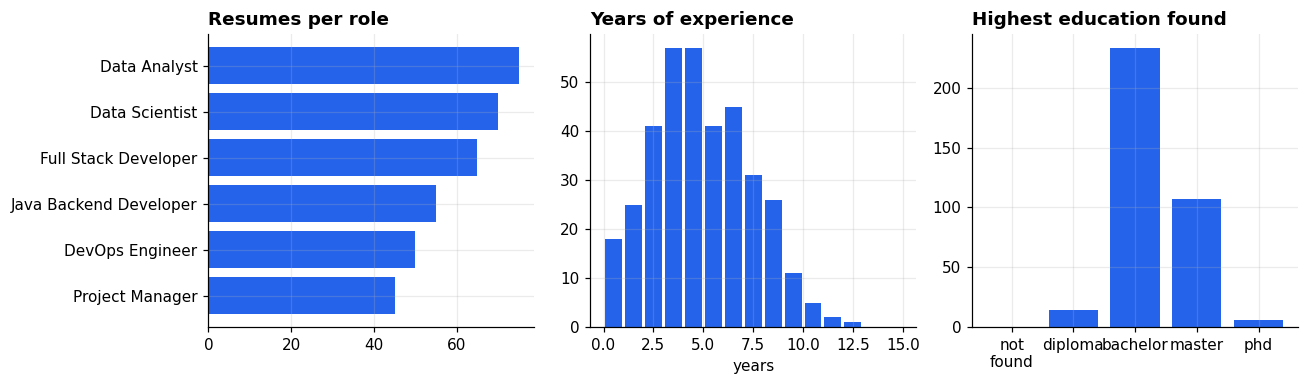

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
counts = pool["category"].value_counts()
axes[0].barh(counts.index[::-1], counts.values[::-1], color=C["blue"])
axes[0].set_title("Resumes per role", loc="left", fontweight="bold")
axes[1].hist(pool["years_exp"], bins=range(0, 16), color=C["blue"], rwidth=0.85)
axes[1].set_title("Years of experience", loc="left", fontweight="bold"); axes[1].set_xlabel("years")
edu = pool["education"].value_counts().reindex(["none", "diploma", "bachelor", "master", "phd"]).fillna(0)
axes[2].bar(["not\nfound", "diploma", "bachelor", "master", "phd"], edu.values, color=C["blue"])
axes[2].set_title("Highest education found", loc="left", fontweight="bold")
plt.tight_layout(); plt.savefig(IMG_DIR / "01_resume_pool_overview.png", bbox_inches="tight"); plt.show()
print(f"Average skills found per resume: {pool['n_skills'].mean():.1f}")

## 4. Job descriptions
A job description is parsed the same way. **Required** skills come from the "Required skills" part, **preferred** skills
from the "Nice to have" part, and the minimum years and education level come from the requirements text. A new job
description can be pasted in later, so nothing here is hard-coded to the six roles.

In [6]:
JOB_DESCRIPTIONS = {
"Data Scientist": """Data Scientist
We are looking for a Data Scientist to build machine learning models that forecast demand and improve customer retention.
Required skills:
- Python with pandas, NumPy and scikit-learn
- Machine learning and statistics
- SQL for data extraction
- Feature engineering
- At least 3 years of experience; Bachelor's degree or higher in a quantitative field
Nice to have:
- Deep learning with TensorFlow or PyTorch
- NLP
- A/B testing
- Docker""",
"Data Analyst": """Data Analyst
Join our insights team to turn raw data into dashboards and reports that guide business decisions.
Required skills:
- SQL and Excel
- Power BI or Tableau
- Data visualization and dashboards
- Statistics and data cleaning
- Python with pandas
- At least 2 years of experience; Bachelor's degree
Nice to have:
- ETL
- Reporting automation
- Google Analytics""",
"Full Stack Developer": """Full Stack Developer
Build and ship customer-facing web applications end to end.
Required skills:
- HTML, CSS and JavaScript
- React and TypeScript
- Node.js and Express
- REST API design
- MongoDB or SQL databases
- Git and responsive design
- At least 3 years of experience; Bachelor's degree
Nice to have:
- Docker
- AWS
- Agile""",
"Java Backend Developer": """Java Backend Developer
Design and maintain scalable backend services for a high-traffic platform.
Required skills:
- Java with Spring Boot and Hibernate
- Microservices and REST API
- MySQL and SQL
- Maven, JUnit and Git
- At least 4 years of experience; Bachelor's degree
Nice to have:
- Kafka
- Docker and Kubernetes
- Jenkins
- AWS""",
"DevOps Engineer": """DevOps Engineer
Own our cloud infrastructure, deployment pipelines and reliability.
Required skills:
- Docker and Kubernetes
- AWS and Terraform
- CI/CD with Jenkins
- Linux and Bash
- Ansible
- Monitoring with Prometheus and Grafana
- At least 3 years of experience; Bachelor's degree
Nice to have:
- Python
- Git
- Microservices""",
"Project Manager": """Project Manager
Lead cross-functional projects from planning to delivery.
Required skills:
- Agile and Scrum
- Jira and MS Project
- Stakeholder management and communication
- Risk management and budgeting
- Project planning and leadership
- At least 5 years of experience; Bachelor's degree
Nice to have:
- PMP
- Reporting
- Power BI""",
}


def parse_jd(text):
    lines = text.strip().splitlines()
    title = lines[0].strip()
    pref_match = re.search(r"(?im)^\s*(nice to have|preferred|bonus|good to have)\b.*$", text)
    before = text[:pref_match.start()] if pref_match else text
    pref_text = text[pref_match.end():] if pref_match else ""
    req_match = re.search(r"(?im)^\s*(required skills?|requirements?|must have)\b.*$", before)
    req_text = before[req_match.end():] if req_match else before
    required = extract_skills(req_text)
    preferred = [s for s in extract_skills(pref_text) if s not in required]
    years = re.findall(r"(\d{1,2})\+?\s*years", req_text, re.I)
    return {"title": title, "required": required, "preferred": preferred,
            "min_years": int(years[0]) if years else 0, "min_edu": EDU_LEVELS[parse_education(req_text)], "text": clean_for_model(text)}


JOBS = {role: parse_jd(txt) for role, txt in JOB_DESCRIPTIONS.items()}
jd = JOBS[TARGET_ROLE]
print(f"Parsed job description: {jd['title']}")
print(f"  required skills : {', '.join(jd['required'])}")
print(f"  preferred skills: {', '.join(jd['preferred'])}")
print(f"  minimum years   : {jd['min_years']}   minimum education level: {jd['min_edu']} (2 = bachelor)")

Parsed job description: Data Scientist
  required skills : feature engineering, machine learning, numpy, pandas, python, scikit-learn, sql, statistics
  preferred skills: a/b testing, deep learning, docker, nlp, pytorch, tensorflow
  minimum years   : 3   minimum education level: 2 (2 = bachelor)


## 5. The ranking model
No single signal ranks resumes well, so the fit score blends five. Each is scaled to 0-1 and weighted
(weights are set in the configuration cell):

| Signal | What it measures | Weight |
|---|---|---|
| **Text similarity** | TF-IDF cosine similarity between the resume and the job description. Rare, specific terms count more than common ones | 30% |
| **Skill coverage** | share of the job's skills the candidate has (required skills count double the preferred ones) | 35% |
| **Role fit (ML)** | a logistic-regression classifier trained on resumes predicts which role a resume belongs to. The score is the chance the resume belongs to the job's role | 20% |
| **Experience** | years of experience against the job's minimum | 7.5% |
| **Education** | education level against the job's minimum | 7.5% |

**Why a classifier too?** Skill matching is literal. The classifier learns the *language of a role* from many
resumes, so it still gives credit when a candidate phrases things differently.

The classifier's probabilities for ranking come from **5-fold out-of-fold predictions**, so no resume is scored by a
model that was trained on it.

Role classifier (5-fold, out-of-fold): accuracy 98.9% | macro F1 98.8%


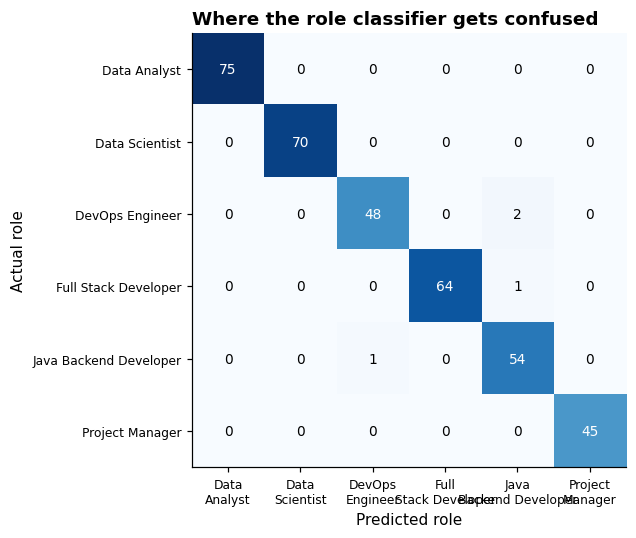

In [7]:
vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, max_features=20000)
X = vectorizer.fit_transform(pool["clean_text"])

classes = sorted(pool["category"].unique())
y = pool["category"].values
clf = LogisticRegression(max_iter=2000, C=10)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
P_oof = cross_val_predict(clf, X, y, cv=cv, method="predict_proba")          # out-of-fold role probabilities
y_pred = np.array(classes)[P_oof.argmax(axis=1)]
clf_full = LogisticRegression(max_iter=2000, C=10).fit(X, y)               # used for new, unseen text

acc, f1 = accuracy_score(y, y_pred), f1_score(y, y_pred, average="macro")
print(f"Role classifier (5-fold, out-of-fold): accuracy {acc:.1%} | macro F1 {f1:.1%}")

cm = confusion_matrix(y, y_pred, labels=classes)
fig, ax = plt.subplots(figsize=(6.4, 5))
ax.imshow(cm, cmap="Blues"); ax.grid(False)
ax.set_xticks(range(len(classes))); ax.set_yticks(range(len(classes)))
ax.set_xticklabels([c.replace(" ", "\n", 1) for c in classes], fontsize=8); ax.set_yticklabels(classes, fontsize=8)
for i in range(len(classes)):
    for j in range(len(classes)):
        ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=9)
ax.set_xlabel("Predicted role"); ax.set_ylabel("Actual role")
ax.set_title("Where the role classifier gets confused", loc="left", fontweight="bold")
plt.tight_layout(); plt.savefig(IMG_DIR / "02_role_classifier_confusion.png", bbox_inches="tight"); plt.show()

In [8]:
def score_pool(jd):
    # Score every resume in the pool against one parsed job description.
    jd_vec = vectorizer.transform([jd["text"]])
    sim = (X @ jd_vec.T).toarray().ravel()
    role_probs_for_jd = clf_full.predict_proba(jd_vec)[0]
    req, pref = set(jd["required"]), set(jd["preferred"])
    wanted = {s: 1.0 for s in req} | {s: 0.5 for s in pref}
    total_w = sum(wanted.values()) or 1

    have = pool["skills"].apply(set)
    out = pd.DataFrame({"resume_id": pool["resume_id"], "name": pool["name"], "category": pool["category"]})
    out["sim_raw"] = sim
    out["tfidf"] = sim / sim.max() if sim.max() > 0 else sim
    out["req_cov"] = have.apply(lambda h: len(h & req) / len(req) if req else 1.0)
    out["skills"] = have.apply(lambda h: sum(w for s, w in wanted.items() if s in h) / total_w)
    out["role_fit"] = P_oof @ role_probs_for_jd
    out["experience"] = np.minimum(1, pool["years_exp"] / jd["min_years"]) if jd["min_years"] else 1.0
    edu = pool["edu_level"].replace(0, np.nan)
    out["education"] = (np.minimum(1, edu / jd["min_edu"]) if jd["min_edu"] else 1.0)
    out["education"] = out["education"].fillna(0.5)
    out["score"] = 100 * sum(WEIGHTS[k] * out[k] for k in WEIGHTS)
    out["years_exp"], out["education_level"] = pool["years_exp"], pool["education"]
    out["matched_required"] = have.apply(lambda h: sorted(h & req))
    out["missing_required"] = have.apply(lambda h: sorted(req - h))
    out["matched_preferred"] = have.apply(lambda h: sorted(h & pref))
    out["missing_preferred"] = have.apply(lambda h: sorted(pref - h))
    out["verdict"] = np.select([out["score"] >= 70, out["score"] >= 50], ["Shortlist", "Review"], "Not a fit")
    return out.sort_values("score", ascending=False).reset_index(drop=True)


ranked = score_pool(jd)
ranked.index = ranked.index + 1
print(f"Top {TOP_N} candidates for: {jd['title']}\n")
ranked.head(TOP_N)[["name", "category", "score", "verdict", "years_exp", "req_cov", "role_fit"]].round(2)

Top 10 candidates for: Data Scientist



,name,category,score,verdict,years_exp,req_cov,role_fit
1,Isha Haddad,Data Scientist,90.88,Shortlist,7,0.88,0.96
2,Omar Novak,Data Scientist,89.94,Shortlist,6,0.75,0.97
3,Kabir Ivanov,Data Scientist,85.70,Shortlist,7,1.00,0.91
4,Priya Tanaka,Data Scientist,85.37,Shortlist,5,0.75,0.96
5,Tara Sharma,Data Scientist,85.23,Shortlist,8,1.00,0.90
6,Maya Tanaka,Data Scientist,85.21,Shortlist,6,0.75,0.96
7,Chloe Mehta,Data Scientist,84.75,Shortlist,7,0.75,0.94
8,Liam Chen,Data Scientist,84.37,Shortlist,6,0.88,0.95
9,Ethan Tanaka,Data Scientist,83.86,Shortlist,5,0.75,0.96
10,Nora Novak,Data Scientist,83.52,Shortlist,6,0.75,0.93


## 6. Does it actually work? Evaluation against simpler methods
A ranking system must be **tested, not trusted**. For each of the six roles, every resume is ranked against that
role's job description, and each method is checked on how many of the top results are genuinely from that role.

| Metric | Meaning |
|---|---|
| **Precision@10** | of the top 10 shown to a recruiter, how many are really from the role |
| **NDCG@10** | like precision, but rewards putting the right people nearer the very top |
| **MAP** | quality of the whole ranking, not only the top |
| **Order check** (simulated data only) | rank correlation between the score and the generator's known true fit, among resumes inside the role. This tests whether a method orders good candidates above weaker ones, not just role versus non-role |

Methods: **keyword match** (count of required skills found, the classic ATS approach), **text similarity** alone,
**role classifier** alone, and the **hybrid** score.

In [9]:
def ranking_metrics(scores, relevant, k=10):
    order = np.argsort(-scores, kind="stable")
    return {"Precision@10": relevant[order[:k]].mean(),
            "NDCG@10": ndcg_score(relevant[None, :].astype(float), scores[None, :], k=k),
            "MAP": average_precision_score(relevant, scores)}


truth_available = "true_quality" in pool.columns
methods = {"Keyword match (count of required skills)": lambda s: s["req_cov"].values,
           "Text similarity only (TF-IDF)": lambda s: s["tfidf"].values,
           "Role classifier only": lambda s: s["role_fit"].values,
           "Hybrid score (this system)": lambda s: s["score"].values}

rows = []
for role in classes:
    if role not in JOBS:
        continue
    s = score_pool(JOBS[role]).set_index("resume_id").loc[pool["resume_id"]]      # back to pool order
    relevant = (pool["category"].values == role).astype(int)
    inside = relevant == 1
    for name, fn in methods.items():
        scores = fn(s)
        r = {"Role": role, "Method": name, **ranking_metrics(scores, relevant)}
        if truth_available:
            r["Order check"] = spearmanr(scores[inside], pool.loc[inside, "true_quality"]).statistic
        rows.append(r)

eval_df = pd.DataFrame(rows)
metric_cols = ["Precision@10", "NDCG@10", "MAP"] + (["Order check"] if truth_available else [])
comparison = eval_df.groupby("Method")[metric_cols].mean().loc[list(methods)]
comparison.to_csv(OUT_DIR / "ranking_method_comparison.csv")
eval_df.to_csv(OUT_DIR / "ranking_evaluation_by_role.csv", index=False)
print(f"Averages across {eval_df['Role'].nunique()} roles (higher is better, 1.00 is perfect):")
comparison.round(3)

Averages across 6 roles (higher is better, 1.00 is perfect):


,Precision@10,NDCG@10,MAP,Order check
Method,,,,
Keyword match (count of required skills),1.0,1.0,0.877,0.896
Text similarity only (TF-IDF),1.0,1.0,0.990,0.619
Role classifier only,1.0,1.0,1.000,0.505
Hybrid score (this system),1.0,1.0,0.997,0.857


Best at telling roles apart (MAP)  : Role classifier only (1.000); keyword matching alone reaches 0.877
Best at ordering within a role    : Keyword match (count of required skills) (0.90); hybrid 0.86


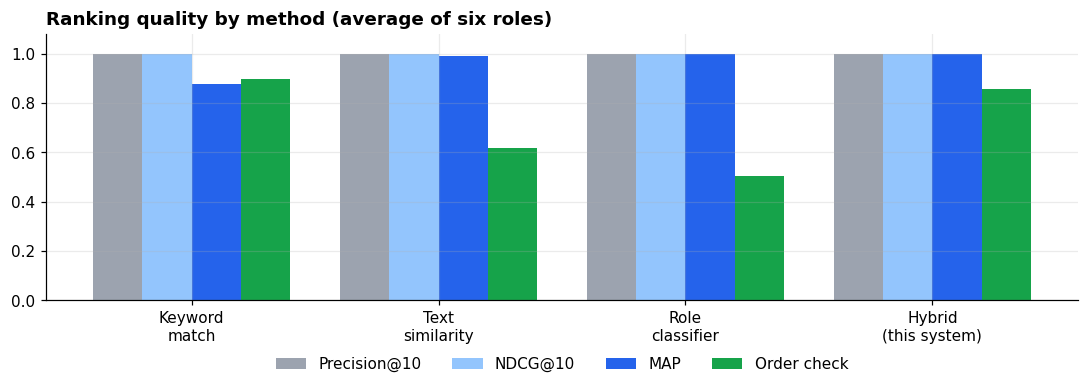

In [10]:
fig, ax = plt.subplots(figsize=(10, 3.8))
names = ["Keyword\nmatch", "Text\nsimilarity", "Role\nclassifier", "Hybrid\n(this system)"]
width, x = 0.2, np.arange(len(names))
shown = ["Precision@10", "NDCG@10", "MAP"] + (["Order check"] if truth_available else [])
palette = [C["grey"], "#93c5fd", C["blue"], C["green"]]
for i, m in enumerate(shown):
    ax.bar(x + (i - (len(shown) - 1) / 2) * width, comparison[m].values, width, label=m, color=palette[i])
ax.set_xticks(x); ax.set_xticklabels(names); ax.set_ylim(0, 1.08)
ax.set_title("Ranking quality by method (average of six roles)", loc="left", fontweight="bold")
ax.legend(frameon=False, ncol=len(shown), loc="lower center", bbox_to_anchor=(0.5, -0.32))
plt.tight_layout(); plt.savefig(IMG_DIR / "03_ranking_method_comparison.png", bbox_inches="tight"); plt.show()

print(f"Best at telling roles apart (MAP)  : {comparison['MAP'].idxmax()} ({comparison['MAP'].max():.3f}); keyword matching alone reaches {comparison.iloc[0]['MAP']:.3f}")
if truth_available:
    print(f"Best at ordering within a role    : {comparison['Order check'].idxmax()} ({comparison['Order check'].max():.2f}); hybrid {comparison.iloc[3]['Order check']:.2f}")

**How to read these results.** The simulated roles use fairly distinct vocabularies, so every method finds the right *role*
easily and the top-10 scores sit near the ceiling. Two differences still show up:

- **Telling neighbouring roles apart (MAP).** Keyword matching is the weakest here, because skills such as Python, SQL and
  pandas appear in several roles. Methods that look at the whole resume separate Data Scientist from Data Analyst better.
- **Ordering candidates inside one role (order check).** Skill coverage is the strongest single signal. The text and
  classifier signals say *which role a resume belongs to*, not *how strong* the candidate is, so on their own they
  order candidates poorly. The hybrid keeps role awareness and still orders candidates well.

Real resumes are far messier than simulated ones, so expect lower numbers on real data and re-check the table.

## 7. Ranked shortlist
Here is the shortlist for the target role. The stacked bar shows **why** each candidate scored what they did, so a
recruiter can see the reasoning, not just a number. Scores of 70 or more are marked *Shortlist*, 50-70 *Review*,
and below 50 *Not a fit*. These cut-offs are starting points and should be tuned with a hiring manager.

Out of 360 resumes: 34 Shortlist, 34 Review, 292 Not a fit
Of the 10 shown, 10 are genuinely Data Scientist resumes.


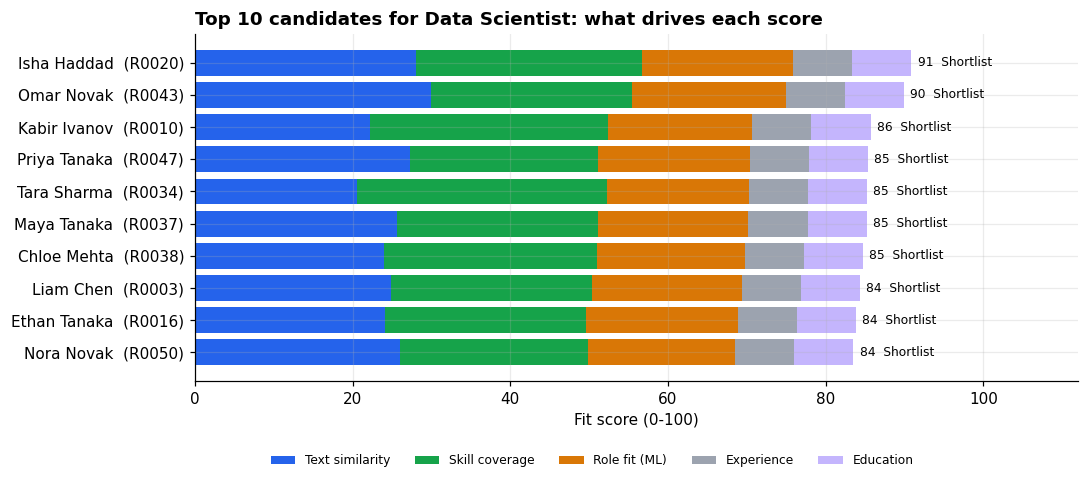

In [11]:
top = ranked.head(TOP_N).iloc[::-1]
labels = [f"{n}  ({r})" for n, r in zip(top["name"], top["resume_id"])]
parts = {"Text similarity": "tfidf", "Skill coverage": "skills", "Role fit (ML)": "role_fit", "Experience": "experience", "Education": "education"}
colors = [C["blue"], C["green"], C["amber"], C["grey"], "#c4b5fd"]

fig, ax = plt.subplots(figsize=(10, 4.6))
left = np.zeros(len(top))
for (label, col), color in zip(parts.items(), colors):
    contribution = WEIGHTS[col] * top[col].values * 100
    ax.barh(labels, contribution, left=left, label=label, color=color)
    left += contribution
for i, (s, v) in enumerate(zip(top["score"], top["verdict"])):
    ax.text(s + 0.8, i, f"{s:.0f}  {v}", va="center", fontsize=8)
ax.set_xlim(0, 112); ax.set_xlabel("Fit score (0-100)")
ax.set_title(f"Top {TOP_N} candidates for {jd['title']}: what drives each score", loc="left", fontweight="bold")
ax.legend(frameon=False, ncol=5, loc="lower center", bbox_to_anchor=(0.45, -0.28), fontsize=8)
plt.tight_layout(); plt.savefig(IMG_DIR / "04_top_candidates_score_breakdown.png", bbox_inches="tight"); plt.show()

counts = ranked["verdict"].value_counts()
print(f"Out of {len(ranked)} resumes: " + ", ".join(f"{counts.get(v, 0)} {v}" for v in ["Shortlist", "Review", "Not a fit"]))
inside = ranked[ranked["category"] == TARGET_ROLE]
print(f"Of the {len(ranked.head(TOP_N))} shown, {int((ranked.head(TOP_N)['category'] == TARGET_ROLE).sum())} are genuinely {TARGET_ROLE} resumes.")

## 8. Skill gap analysis
This answers the second half of the brief: *what is missing?* The heatmap compares the top candidates with every
skill the job asks for. Green means the skill was found, red means it is missing. The bar chart zooms out to show
which required skills the **applicant pool** is short of, which is useful for sourcing and for training plans.

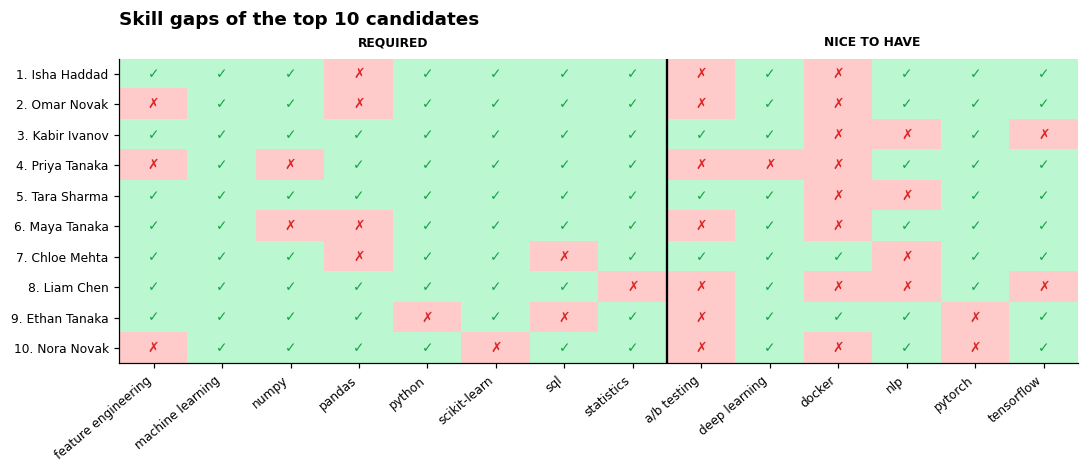

In [12]:
need = jd["required"] + jd["preferred"]
top10 = ranked.head(TOP_N)
grid = np.array([[1 if s in (m_r + m_p) else 0 for s in need]
                 for m_r, m_p in zip(top10["matched_required"], top10["matched_preferred"])])

fig, ax = plt.subplots(figsize=(10, 4.4))
ax.imshow(grid, cmap=plt.matplotlib.colors.ListedColormap(["#fecaca", "#bbf7d0"]), aspect="auto"); ax.grid(False)
ax.set_xticks(range(len(need))); ax.set_xticklabels(need, rotation=40, ha="right", fontsize=8)
ax.set_yticks(range(len(top10))); ax.set_yticklabels([f"{i + 1}. {n}" for i, n in enumerate(top10["name"])], fontsize=8)
for i in range(grid.shape[0]):
    for j in range(grid.shape[1]):
        ax.text(j, i, "✓" if grid[i, j] else "✗", ha="center", va="center", fontsize=9, color=C["green"] if grid[i, j] else C["red"])
ax.axvline(len(jd["required"]) - 0.5, color="k", lw=1.5)
ax.text(len(jd["required"]) / 2 - 0.5, -0.9, "REQUIRED", ha="center", fontsize=8, fontweight="bold")
ax.text(len(jd["required"]) + len(jd["preferred"]) / 2 - 0.5, -0.9, "NICE TO HAVE", ha="center", fontsize=8, fontweight="bold")
ax.set_title(f"Skill gaps of the top {TOP_N} candidates", loc="left", fontweight="bold", pad=22)
plt.tight_layout(); plt.savefig(IMG_DIR / "05_skill_gap_heatmap.png", bbox_inches="tight"); plt.show()

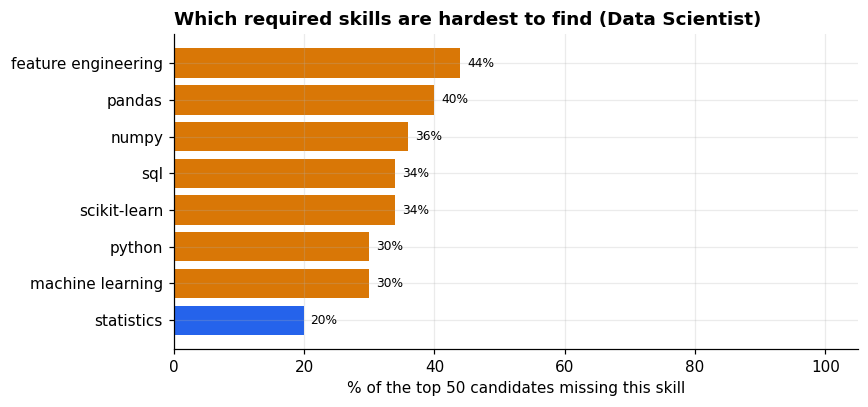

,resume_id,name,score,verdict,years_exp,education_level,gap_summary
1,R0020,Isha Haddad,90.9,Shortlist,7,bachelor,Has 7 of 8 required skills. Missing: pandas.
2,R0043,Omar Novak,89.9,Shortlist,6,bachelor,"Has 6 of 8 required skills. Missing: feature engineering, pandas."
3,R0010,Kabir Ivanov,85.7,Shortlist,7,master,"Meets every required skill. Nice-to-have gaps: docker, nlp, tensorflow."
4,R0047,Priya Tanaka,85.4,Shortlist,5,master,"Has 6 of 8 required skills. Missing: feature engineering, numpy."
5,R0034,Tara Sharma,85.2,Shortlist,8,bachelor,"Meets every required skill. Nice-to-have gaps: docker, nlp."
6,R0037,Maya Tanaka,85.2,Shortlist,6,master,"Has 6 of 8 required skills. Missing: numpy, pandas."


In [13]:
top50 = ranked.head(50)
miss_rate = pd.Series({s: np.mean([s in m for m in top50["missing_required"]]) * 100 for s in jd["required"]}).sort_values()

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(miss_rate.index, miss_rate.values, color=[C["red"] if v > 50 else C["amber"] if v > 25 else C["blue"] for v in miss_rate.values])
for i, v in enumerate(miss_rate.values):
    ax.text(v + 1, i, f"{v:.0f}%", va="center", fontsize=8)
ax.set_xlim(0, 105); ax.set_xlabel("% of the top 50 candidates missing this skill")
ax.set_title(f"Which required skills are hardest to find ({jd['title']})", loc="left", fontweight="bold")
plt.tight_layout(); plt.savefig(IMG_DIR / "06_pool_skill_shortage.png", bbox_inches="tight"); plt.show()


def gap_sentence(r):
    if not r["missing_required"]:
        extra = f" Nice-to-have gaps: {', '.join(r['missing_preferred'])}." if r["missing_preferred"] else ""
        return "Meets every required skill." + extra
    return (f"Has {len(r['matched_required'])} of {len(r['matched_required']) + len(r['missing_required'])} required skills. "
            f"Missing: {', '.join(r['missing_required'])}.")


gaps = ranked.head(TOP_N).copy()
gaps["gap_summary"] = gaps.apply(gap_sentence, axis=1)
report = gaps[["resume_id", "name", "score", "verdict", "years_exp", "education_level", "gap_summary"]].round(1)
report.to_csv(OUT_DIR / f"skill_gap_report_{TARGET_ROLE.lower().replace(' ', '_')}.csv")
ranked.assign(**{c: ranked[c].str.join(", ") for c in ["matched_required", "missing_required", "matched_preferred", "missing_preferred"]}
              ).drop(columns=["sim_raw"]).round(3).to_csv(OUT_DIR / f"ranked_candidates_{TARGET_ROLE.lower().replace(' ', '_')}.csv", index_label="rank")
report.head(6)

## 9. Screen a new job description
Everything above works for any job description, not only the six built in. Paste new text, and the system
extracts its requirements, ranks the pool, and reports the gaps. The role-fit signal is computed by classifying the
job description itself, so no role label is needed.

In [14]:
new_jd_text = """Junior Data Analyst (Retail)
We need an analyst to track store performance and build weekly dashboards for regional managers.
Required skills:
- SQL and Excel
- Power BI or Tableau
- Dashboards and reporting
- Data cleaning
- At least 1 years of experience
Nice to have:
- Python
- Statistics"""

new_jd = parse_jd(new_jd_text)
new_ranked = score_pool(new_jd)
print(f"Job: {new_jd['title']}")
print(f"Required : {', '.join(new_jd['required'])}")
print(f"Preferred: {', '.join(new_jd['preferred'])}\n")
new_ranked.index = new_ranked.index + 1
show = new_ranked.head(5).copy()
show["gap_summary"] = show.apply(gap_sentence, axis=1)
show[["name", "category", "score", "verdict", "gap_summary"]].round(1)

Job: Junior Data Analyst (Retail)
Required : dashboards, data cleaning, excel, power bi, reporting, sql, tableau
Preferred: python, statistics



,name,category,score,verdict,gap_summary
1,Priya Mehta,Data Analyst,95.1,Shortlist,Meets every required skill.
2,Chloe Novak,Data Analyst,90.4,Shortlist,Has 6 of 7 required skills. Missing: dashboards.
3,Sofia Costa,Data Analyst,90.0,Shortlist,Has 6 of 7 required skills. Missing: excel.
4,Elena Kim,Data Analyst,88.6,Shortlist,Meets every required skill.
5,Ivan Chen,Data Analyst,87.8,Shortlist,Meets every required skill.


## 10. What this means for the business
The numbers below are computed from the run, so they update with the data.

In [15]:
n = len(pool)
shortlist = int((ranked["score"] >= 70).sum())
review = int(((ranked["score"] >= 50) & (ranked["score"] < 70)).sum())
minutes_each = 6                                  # assumption: manual first-pass read of one resume
saved_hours = n * minutes_each / 60
share_in_role = (ranked.head(TOP_N)["category"] == TARGET_ROLE).mean() * 100
hardest = miss_rate.sort_values(ascending=False)

print(f"SCREENING SUMMARY: {jd['title']} | {n} applicants")
print("-" * 70)
print(f"Shortlist (score >= 70)   : {shortlist} candidates   |   Review (50-70): {review}   |   Not a fit: {n - shortlist - review}")
print(f"Recruiter reading time    : about {saved_hours:.0f} hours for a first read of all {n} resumes (at ~{minutes_each} min each)")
print(f"                            about {(shortlist + review) * minutes_each / 60:.0f} hours if people read only the {shortlist + review} Shortlist + Review candidates")
print(f"Top-{TOP_N} relevance          : {share_in_role:.0f}% of the top {TOP_N} are genuinely {TARGET_ROLE} profiles")
print(f"Hardest required skills   : {hardest.index[0]} ({hardest.iloc[0]:.0f}% of top-50 candidates lack it), {hardest.index[1]} ({hardest.iloc[1]:.0f}%)")
print(f"Best candidate            : {ranked.iloc[0]['name']} (score {ranked.iloc[0]['score']:.0f}); {gap_sentence(ranked.iloc[0])}")

SCREENING SUMMARY: Data Scientist | 360 applicants
----------------------------------------------------------------------
Shortlist (score >= 70)   : 34 candidates   |   Review (50-70): 34   |   Not a fit: 292
Recruiter reading time    : about 36 hours for a first read of all 360 resumes (at ~6 min each)
                            about 7 hours if people read only the 68 Shortlist + Review candidates
Top-10 relevance          : 100% of the top 10 are genuinely Data Scientist profiles
Hardest required skills   : feature engineering (44% of top-50 candidates lack it), pandas (40%)
Best candidate            : Isha Haddad (score 91); Has 7 of 8 required skills. Missing: pandas.


### How a company would use it
| Step | Use |
|---|---|
| **First pass** | Sort every applicant by fit score. Interview from the top, and have a person skim the Review band before rejecting anyone |
| **Explain decisions** | The score breakdown and gap summary give recruiters and candidates a concrete reason, not a black box |
| **Interview focus** | Use each shortlisted candidate's missing skills as the questions to probe in the interview |
| **Sourcing and training** | If a required skill is missing in most of the pool, widen the search or plan to train for it |
| **Job description quality** | If a *required* skill is rare, check whether it really is required. Over-long requirement lists shrink the pool |

### Responsible use and limitations
- **This ranks, it does not decide.** Keep a human in the loop. Low scores should never auto-reject anyone.
- **Bias.** The model never sees names, emails or photos, but proxies can leak (schools, locations, career gaps). Audit
  shortlists by group before using any screening tool on real candidates, and keep records.
- **Literal skill matching.** Skills missing from the taxonomy are invisible. Extend `SKILLS` for new roles.
- **Simulated data.** Results here show the pipeline works on controlled data. On real resumes, accuracy will be lower
  and the weights should be re-tuned against hiring outcomes.
- **Next steps:** add semantic embeddings for fuzzy skill matching, parse PDFs directly, learn the weights from past
  hiring decisions, and track shortlist fairness over time.